# Notebook 5 of 6 — IV. Open-ended section
## Can the model be trusted to drive commercial actions?
**Group XX**

A good F1 on Kaggle does not tell the company whether it can *act* on the model. Before a sales team uses it, three questions need an answer:

| | Objective | Method |
|---|---|---|
| **O1** | **What information does the model rely on?** Which groups of inputs carry the prediction, and is any group unnecessary? | Ablation study: remove one information group at a time, refit the whole pipeline in every window, measure the loss of ROC-AUC (paired by window) |
| **O2** | **Are its probabilities honest?** If it says 70 %, do about 70 % of those customers come back? | Reliability table on out-of-window predictions, confidence vs. accuracy, and probability calibration (`CalibratedClassifierCV`, sigmoid and isotonic, week 7) |
| **O3** | **Where does it fail, and how should it be used for a retention campaign?** | Error analysis by customer segment, and the share of real non-repeaters reached when the lowest-probability purchases are contacted |

> **New in Part 2:** the homework had no open-ended section. The tools are the ones already used in Part 1 and in the earlier notebooks (the same windows, pipeline and `paired_delta` comparison), plus calibration from week 7.

All analyses use the final configuration of notebook 04 on the development windows (out-of-window predictions only). The holdout is used once more at the end of O3, only to confirm a result, never to choose anything.

In [1]:
import json
import tempfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from joblib import Memory
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import log_loss, roc_auc_score

import project_pipeline as pp

warnings.filterwarnings("ignore", message="Found unknown categories")
# In the ablation some variants have fewer than 60 columns: RFE then keeps all of them (intended).
warnings.filterwarnings("ignore", message="Found n_features_to_select")
pd.set_option("display.width", 170)
BLUE, ORANGE, GREY = "#1779A8", "#C96A00", "#8C8C8C"

train, test, _ = pp.load_raw(pp.find_data_folder())
design = pp.development_split(train)
X, y, folds = design.X_dev, design.y_dev, design.folds
config = json.loads(Path("outputs/final_config.json").read_text())
THRESHOLD = config["threshold"]
cache_folder = tempfile.TemporaryDirectory()
memory = Memory(cache_folder.name, verbose=0)
print(f"Final model: {config['model']} | threshold {THRESHOLD}")

# Out-of-window predictions of the final configuration: every purchase is predicted by a model
# trained only on purchases more than 90 days earlier (same design as notebooks 02-04).
reference_scores, oof = pp.cross_validate_time(pp.final_pipeline(config, memory=memory), X, y, folds)
scored = oof.notna()
print(f"Out-of-window predictions: {scored.sum()} purchases, mean ROC-AUC {reference_scores['ROC_AUC'].mean():.4f}")

Final model: ExtraTrees | threshold 0.43
Out-of-window predictions: 3531 purchases, mean ROC-AUC 0.7996


## O1 — What information does the model rely on?

The inputs are split into the seven information groups of notebook 01 (each engineered feature belongs to the group whose behaviour it describes). For each group, the whole pipeline — preprocessing, vote selection and the tuned model — is refitted **without that group** in every window. A large drop means the group carries information that nothing else replaces; no drop means the rest of the inputs already contain it. Two larger variants remove whole blocks: a "history only" model (does the current purchase and its context matter at all?) and a model with no customer history.

In [2]:
for group, columns in pp.FEATURE_GROUPS.items():
    print(f"{group:30s} {len(columns):2d} inputs: {', '.join(columns[:6])}{' ...' if len(columns) > 6 else ''}")

ablations = {f"without {group}": tuple(columns) for group, columns in pp.FEATURE_GROUPS.items()}
history = ["history timing", "history value", "rolling counts", "rolling spend"]
ablations["history only (no current purchase, context or month)"] = tuple(
    c for g, cols in pp.FEATURE_GROUPS.items() if g not in history for c in cols)
ablations["no customer history (current purchase, context, month)"] = tuple(
    c for g in history for c in pp.FEATURE_GROUPS[g])

rows = []
for name, dropped in ablations.items():
    table, _ = pp.cross_validate_time(pp.final_pipeline(config, memory=memory, drop=dropped), X, y, folds)
    rows.append({"variant": name, "ROC-AUC": table["ROC_AUC"].mean(),
                 **pp.paired_delta(table["ROC_AUC"], reference_scores["ROC_AUC"])})
ablation = pd.DataFrame(rows).set_index("variant").sort_values("mean_diff")
display(ablation.round(4))

current purchase               11 inputs: Total Liquido, Total Imp_, Total Portes, Total Desc_ Global, Total Desc_ Linha, Custo ...
history timing                  8 inputs: days_since_previous_purchase, customer_tenure_days, prior_purchase_count, prior_mean_gap_days, prior_std_gap_days, first_purchase ...
history value                   6 inputs: prior_total_spend, prior_mean_purchase_value, prior_std_purchase_value, prior_min_purchase_value, prior_max_purchase_value, ticket_vs_history
rolling counts                  5 inputs: purchase_count_30d, purchase_count_90d, purchase_count_180d, purchase_count_365d, recent_activity_share
rolling spend                   4 inputs: spend_30d, spend_90d, spend_180d, spend_365d
sale context (categoricals)     6 inputs: payment_type, salesperson, commercial_zone, transport_method, warehouse, document_series
purchase month                  1 inputs: purchase_month


,ROC-AUC,mean_diff,SEM,wins,verdict
variant,,,,,
"no customer history (current purchase, context, month)",0.7337,-0.0658,0.0131,0/5,worse
"history only (no current purchase, context or month)",0.7821,-0.0175,0.0062,0/5,worse
without current purchase,0.7931,-0.0065,0.0014,0/5,worse
without sale context (categoricals),0.7935,-0.0061,0.0040,1/5,inside the noise
without purchase month,0.7951,-0.0045,0.0035,2/5,inside the noise
without rolling counts,0.7957,-0.0039,0.0014,1/5,worse
without rolling spend,0.7966,-0.0029,0.0015,1/5,inside the noise
without history timing,0.7970,-0.0026,0.0011,1/5,worse
without history value,0.7984,-0.0012,0.0010,2/5,inside the noise


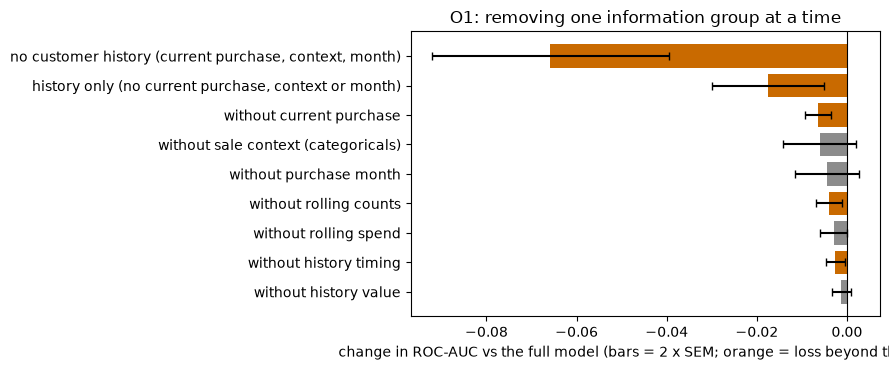

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
colours = [ORANGE if v == "worse" else GREY for v in ablation["verdict"]]
ax.barh(ablation.index, ablation["mean_diff"], xerr=2 * ablation["SEM"], color=colours, capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.invert_yaxis()
ax.set(xlabel="change in ROC-AUC vs the full model (bars = 2 x SEM; orange = loss beyond the noise)",
       title="O1: removing one information group at a time")
plt.tight_layout()
plt.show()

- **Customer history is the backbone.** Without any history column the model falls to 0.734 AUC (−0.066 in every window), while history alone keeps most of the performance (−0.018). The no-history model still ranks better than chance mainly because transport and payment levels partly identify regular customers (notebook 01, Section 2.7).
- **No single history group is indispensable.** Removing timing, rolling counts, rolling spend or history value costs only 0.001–0.004 AUC: the four groups describe the same rhythm in overlapping ways (the redundancy found in notebook 03), so each can stand in for another.
- **The current purchase adds information that nothing else replaces**: removing it costs 0.0065 AUC in every window (0/5 wins). Together with the sale context and the month, the non-history inputs are worth about 0.018 AUC.
- The sale context (−0.006) and the purchase month (−0.0045) help on average but not beyond the noise on their own: useful, not essential.

For the company this means that the quality of the history columns matters most, and that a much simpler model built on history alone would lose about 0.02 AUC.

## O2 — Are the probabilities honest?

A model is **calibrated** when, among the purchases it scores near *p*, a share near *p* is followed by another purchase (week 7). F1 cannot see this: it only checks labels. The reliability table groups the out-of-window predictions into ten probability bins and compares the average prediction with the observed repeat rate; the **calibration gap** is the average distance between the two, weighted by the number of purchases in each bin. We also compare average **confidence** (the probability given to the predicted label) with **accuracy**, and the log-loss.

`CalibratedClassifierCV` is then tried with both methods taught in class. It is wrapped around the whole pipeline, so in every window it splits the *training* rows into 5 internal folds, fits the pipeline on four and learns the probability map on the fifth: the validation window is still never seen.

In [4]:
def reliability(probability, outcome, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    groups = pd.cut(probability, edges, include_lowest=True)
    table = pd.DataFrame({"p": probability, "y": outcome}).groupby(groups, observed=True).agg(
        purchases=("y", "size"), mean_prediction=("p", "mean"), observed_rate=("y", "mean"))
    gap = np.average((table["observed_rate"] - table["mean_prediction"]).abs(), weights=table["purchases"])
    return table, gap

def probability_report(probability, outcome):
    predicted = (probability >= 0.5).astype(int)
    confidence = np.where(predicted == 1, probability, 1 - probability).mean()
    return {"ROC-AUC": roc_auc_score(outcome, probability), "log-loss": log_loss(outcome, probability),
            "calibration gap": reliability(probability, outcome)[1],
            "confidence": confidence, "accuracy (0.5)": (predicted == outcome).mean(),
            "mean prediction": probability.mean(), "repeat rate": outcome.mean()}

probabilities = {"uncalibrated": oof[scored]}
for method in ["sigmoid", "isotonic"]:
    calibrated = CalibratedClassifierCV(pp.final_pipeline(config, memory=memory), method=method, cv=5)
    _, calibrated_oof = pp.cross_validate_time(calibrated, X, y, folds)
    probabilities[method] = calibrated_oof[scored]
y_scored = y[scored]
display(pd.DataFrame({name: probability_report(p.to_numpy(), y_scored.to_numpy())
                      for name, p in probabilities.items()}).T.round(4))
table, _ = reliability(probabilities["uncalibrated"].to_numpy(), y_scored.to_numpy())
display(table.round(3))

,ROC-AUC,log-loss,calibration gap,confidence,accuracy (0.5),mean prediction,repeat rate
uncalibrated,0.7949,0.5382,0.0376,0.6929,0.7196,0.5633,0.5435
sigmoid,0.7947,0.5431,0.0403,0.7065,0.7210,0.5686,0.5435
isotonic,0.7937,0.5444,0.0317,0.7162,0.7236,0.5722,0.5435


,purchases,mean_prediction,observed_rate
"(0.1, 0.2]",53,0.177,0.189
"(0.2, 0.3]",361,0.257,0.235
"(0.3, 0.4]",641,0.352,0.279
"(0.4, 0.5]",575,0.449,0.400
"(0.5, 0.6]",439,0.549,0.508
"(0.6, 0.7]",431,0.649,0.671
"(0.7, 0.8]",399,0.748,0.747
"(0.8, 0.9]",249,0.844,0.904
"(0.9, 1.0]",383,0.975,0.992


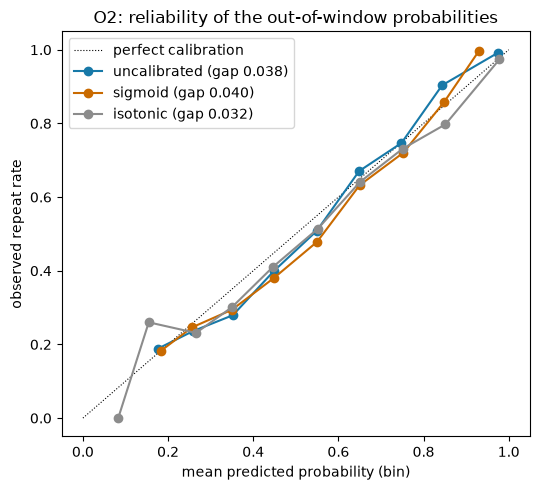

,actual repeat rate,mean prediction (uncalibrated),mean prediction (sigmoid),mean prediction (isotonic)
window,,,,
1,0.528,0.584,0.588,0.604
2,0.588,0.572,0.577,0.579
3,0.547,0.547,0.551,0.552
4,0.486,0.585,0.595,0.597
5,0.564,0.537,0.540,0.539


In [5]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color="black", linewidth=0.8, linestyle=":", label="perfect calibration")
for (name, p), colour in zip(probabilities.items(), (BLUE, ORANGE, GREY)):
    table, gap = reliability(p.to_numpy(), y_scored.to_numpy())
    ax.plot(table["mean_prediction"], table["observed_rate"], marker="o", color=colour, label=f"{name} (gap {gap:.3f})")
ax.set(xlabel="mean predicted probability (bin)", ylabel="observed repeat rate",
       title="O2: reliability of the out-of-window probabilities")
ax.legend()
plt.tight_layout()
plt.show()

# Calibration across time: average prediction vs actual repeat rate in each window.
by_window = pd.DataFrame({
    "actual repeat rate": [y.iloc[b].mean() for _, b in folds],
    **{f"mean prediction ({name})": [p.reindex(X.index[b]).mean() for _, b in folds]
       for name, p in probabilities.items()}}, index=pd.Index(range(1, 6), name="window"))
display(by_window.round(3))

- **The probabilities are already reasonably honest.** The calibration gap is 0.038: predictions between 0.3 and 0.5 are about 5–7 points too high, the top bins slightly too low, and average confidence (0.69) is close to accuracy (0.72), so the model is neither clearly over- nor under-confident.
- **Calibration does not help.** Sigmoid worsens the gap (0.040) and isotonic improves it only slightly (0.032), while both increase the log-loss and slightly lower the ROC-AUC. A calibration step would add complexity for nothing, so **it is not added to the pipeline**.
- **The real risk is drift between years, not the shape of the curve.** In four windows the average prediction is within 0.04 of the actual repeat rate, but in window 4 the model expects 0.59 while only 0.49 of purchases repeat: a year with unusually few repeats cannot be anticipated from past behaviour. Absolute forecasts ("how many customers will come back") should therefore be monitored and the model refitted regularly; rankings are less affected.

## O3 — Where does the model fail, and how should it be used?

### Errors by customer segment
The out-of-window predictions are split by the length of the customer's history, by recency and by whether the purchase falls in a peak month of the buying cycle (notebook 01, Section 2.6). Labels use the competition threshold.

In [6]:
frame = pp.clean_purchases(X[scored]).assign(y=y_scored, p=oof[scored])
frame["predicted"] = (frame["p"] >= THRESHOLD).astype(int)
segments = {
    "history": pd.cut(frame["prior_purchase_count"], [-1, 0, 4, 19, np.inf],
                      labels=["first purchase", "1-4 earlier", "5-19 earlier", "20+ earlier"]),
    "recency": pd.cut(frame["days_since_previous_purchase"].fillna(-1), [-2, -0.5, 30, 90, np.inf],
                      labels=["no previous purchase", "<= 30 days", "31-90 days", "> 90 days"]),
    "calendar": np.where(frame[pp.DATE].dt.month.isin([3, 7, 11]), "peak month (3, 7, 11)", "other month"),
}
rows = []
errors_total = (frame["predicted"] != frame["y"]).sum()
for segment, labels in segments.items():
    for label, part in frame.groupby(labels, observed=True):
        wrong = part["predicted"] != part["y"]
        rows.append({"segment": segment, "group": label, "purchases": len(part),
                     "repeat rate": part["y"].mean(),
                     "ROC-AUC": roc_auc_score(part["y"], part["p"]) if part["y"].nunique() == 2 else np.nan,
                     "accuracy": 1 - wrong.mean(),
                     "missed non-repeats": ((part["predicted"] == 1) & (part["y"] == 0)).sum() / max((part["y"] == 0).sum(), 1),
                     "share of all errors": wrong.sum() / errors_total})
display(pd.DataFrame(rows).set_index(["segment", "group"]).round(3))

purchases  repeat rate  ROC-AUC  accuracy  missed non-repeats  share of all errors
segment  group                                                                                                    
history  first purchase               213        0.258    0.552     0.662               0.196                0.069
         1-4 earlier                  558        0.328    0.608     0.597               0.331                0.214
         5-19 earlier                1259        0.422    0.696     0.642               0.391                0.430
         20+ earlier                 1501        0.766    0.810     0.799               0.783                0.288
recency  no previous purchase         319        0.342    0.721     0.683               0.262                0.096
         <= 30 days                  1171        0.722    0.852     0.781               0.672                0.244
         31-90 days                   688        0.645    0.717     0.688               0.803                0.205
         > 90 days                   1353        0.385    0.674     0.647               0.294                0.455
calendar other month                 2038        0.607    0.797     0.711               0.516                0.560
         peak month (3, 7, 11)       1493        0.456    0.775     0.691               0.372                0.440

- **First purchases are almost unpredictable** (ROC-AUC 0.55): with no history, the model has little to work with. Customers with 20 or more earlier purchases are predicted well (AUC 0.81, 80 % accuracy).
- **Most errors come from the middle**: customers with 5–19 earlier purchases (43 % of all errors) and purchases made more than 90 days after the previous one (46 %). These are the customers whose rhythm is changing, the hardest and most valuable cases for retention.
- Purchases in peak months repeat less (46 % vs 61 %) and are slightly harder to rank (0.775 vs 0.797).
- With the competition threshold (0.43), many non-repeats of loyal customers are labelled "repeat" (78 % for the 20+ segment): the threshold is tuned for F1, not for retention.

### Using the probabilities for a retention campaign
A retention campaign does not need labels: after each purchase, the sales team can contact the purchases with the **lowest** repeat probability. The table shows, for several campaign sizes, how many contacted purchases really are non-repeats (precision) and which share of all non-repeats is reached (coverage), compared with contacting purchases at random. The last rows repeat the calculation on the sealed holdout with the model of notebook 04, as a confirmation only.

In [7]:
def campaign(probability, outcome, shares=(0.1, 0.2, 0.3, 0.4, 0.5)):
    order = np.argsort(probability)                 # lowest repeat probability first
    non_repeat = (np.asarray(outcome)[order] == 0)
    rows = []
    for share in shares:
        contacted = int(round(share * len(order)))
        hit = non_repeat[:contacted]
        rows.append({"contact lowest": f"{share:.0%}", "non-repeats among contacted": hit.mean(),
                     "share of all non-repeats reached": hit.sum() / non_repeat.sum(),
                     "lift vs random": hit.mean() / non_repeat.mean()})
    return pd.DataFrame(rows).set_index("contact lowest")

print(f"Development windows: non-repeat rate {1 - y_scored.mean():.3f}")
display(campaign(oof[scored].to_numpy(), y_scored.to_numpy()).round(3))

holdout_model = pp.final_pipeline(config, memory=memory).fit(X, y)
holdout_probability = holdout_model.predict_proba(design.X_hold)[:, 1]
print(f"Holdout (confirmation only): non-repeat rate {1 - design.y_hold.mean():.3f}")
display(campaign(holdout_probability, design.y_hold.to_numpy()).round(3))
cache_folder.cleanup()

Development windows: non-repeat rate 0.457


,non-repeats among contacted,share of all non-repeats reached,lift vs random
contact lowest,,,
10%,0.796,0.174,1.744
20%,0.756,0.331,1.657
30%,0.740,0.486,1.622
40%,0.710,0.622,1.554
50%,0.680,0.745,1.490


Holdout (confirmation only): non-repeat rate 0.415


,non-repeats among contacted,share of all non-repeats reached,lift vs random
contact lowest,,,
10%,0.797,0.192,1.921
20%,0.784,0.377,1.888
30%,0.740,0.536,1.783
40%,0.690,0.666,1.663
50%,0.647,0.779,1.558


Ranking works much better than the labels suggest. Contacting the **20 % of purchases with the lowest probability reaches non-repeats 76 % of the time** (against 46 % at random, a lift of 1.7) and covers a third of all non-repeats; contacting 10 % reaches 80 %. The holdout confirms it (78 % at 20 %, lift 1.9). For a retention campaign the company should therefore **use the probability ranking and a contact budget**, not the F1 threshold used for Kaggle.

## Key takeaways

| Objective | Answer |
|---|---|
| **O1** What does the model rely on? | Customer history (≈ all the signal, spread over four interchangeable groups); the current purchase adds a small, consistent gain; context and month help marginally. |
| **O2** Are the probabilities honest? | Yes, on average (gap 0.04; calibration methods do not improve it), but the yearly repeat rate can drift by up to 0.10, so absolute forecasts need monitoring and regular refits. |
| **O3** Where does it fail, how to use it? | Nearly blind on first purchases (AUC 0.55) and weakest for mid-history customers whose rhythm is changing. For retention, contact the lowest-probability purchases within a budget: the bottom 20 % are non-repeats 3 times out of 4. |

**Recommendation to the business:** use the model to *rank* returning customers after each purchase and size campaigns by budget; handle first-time customers with a separate rule (for example, a standard onboarding contact), since the model cannot tell them apart; refit at least once a year and track the predicted vs actual repeat rate.